# Mean shift

In [1]:
print("What is mean shift ?")

What is mean shift ?


Mean shift is a non-parametric, density-based unsupervised clustering algorithm that iteratively shifts data points toward the densest regions (modes) in a dataset

# For more information click in the link below

https://docs.google.com/document/d/1FCD07ZFyiyEA2YYIyLBZJPN38OQDiEA9Doah2b-yQTI/edit?usp=sharing

# Notes and interview question and answer

https://docs.google.com/document/d/1gJgSbxdTeYoveGoH3xcZEcMpQxJ_UJX5Qjujz2W5TD8/edit?usp=sharing

# Coding

# Import libraries 


In [16]:
# NumPy → numerical calculations
import numpy as np

# Pandas → data manipulation
import pandas as pd

# Matplotlib → visualization
import matplotlib.pyplot as plt

# make_blobs → creates synthetic clustering data
from sklearn.datasets import make_blobs

# StandardScaler → standardizes features
from sklearn.preprocessing import StandardScaler

# MeanShift → Mean Shift clustering algorithm
from sklearn.cluster import MeanShift

# Silhouette Score → evaluates clustering quality
from sklearn.metrics import silhouette_score

# estimate_bandwidth → estimates a suitable bandwidth
from sklearn.cluster import estimate_bandwidth

# Create the dataset

In [29]:
X, y = make_blobs(
    n_samples=500,                        # Generate 500 observations
    centers=3,                            # Generate 3 natural dense groups
    cluster_std=1.0,                      # Controls spread of each group
    random_state=42                       # Makes the dataset reproducible
)

# Visualize the original data

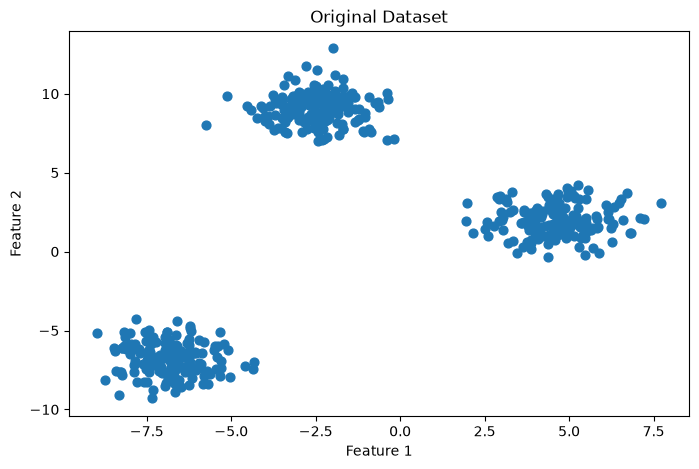

In [30]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],                              # First feature
    X[:, 1],                              # Second feature
    s=40                                  # Point size
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Original Dataset")

plt.show()

# Scale the data 

`Mean shift is distance - based, so scaling is useful when features have different scales`

In [18]:
scaler = StandardScaler()                # Creates the standardization object

X_scaled = scaler.fit_transform(
    X                                     # Standardizes the features
)

# Estimate bandwidth 
`One useful approach is to let scikit-learn estimate ressonable starting bandwidth`

In [31]:
bandwidth = estimate_bandwidth(
    X_scaled,                             # Dataset used to estimate density scale
    quantile=0.2,                         # Controls the neighborhood size used for estimation
    n_samples=500                         # Number of samples considered
)

print("Estimated bandwidth:", bandwidth)

Estimated bandwidth: 0.3375832047143158


# Train Mean shift 


In [20]:
mean_shift = MeanShift(
    bandwidth=bandwidth,                  # Size of the density-search window
    bin_seeding=True                      # Speeds initialization by using binned data locations
)

clusters = mean_shift.fit_predict(
    X_scaled                             # Learn density peaks and assign clusters
)

# Notice no n_cluster  , this is the major difference from k-means.

# How many cluster did mean shift find ?

In [21]:
n_clusters = len(
    np.unique(clusters)                   # Count unique cluster IDs
)

print("Number of clusters:", n_clusters)


# Mean Shift discovered the number of clusters automatically.

# That's one of its biggest advantages.

Number of clusters: 3


# Find the cluster centers 
` mean shift gives us: `


In [22]:
centers = mean_shift.cluster_centers_     # Density peak locations

print(centers)

[[-1.1101512  -1.25406262]
 [-0.21299321  1.15755111]
 [ 1.29915943  0.06951091]]


# Evaluate the clustering 

`We can use the silhouette score`

In [23]:
silhouette = silhouette_score(
    X_scaled,                             # Feature data
    clusters                              # Mean Shift cluster assignments
)

print("Silhouette Score:", silhouette)


# Higher is generally better . 

Silhouette Score: 0.8438960565792794


# Visualize the mean shift

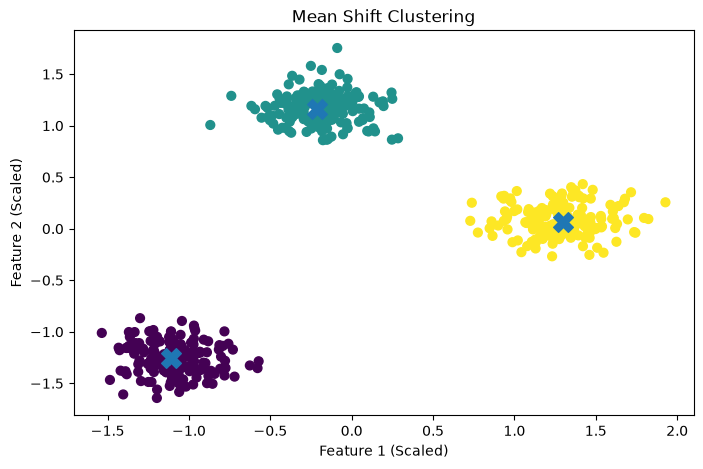

In [26]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],                       # First feature
    X_scaled[:, 1],                       # Second feature
    c=clusters,                           # Color according to cluster
    s=40                                  # Point size
)

plt.scatter(
    centers[:, 0],                        # Cluster center X-coordinate
    centers[:, 1],                        # Cluster center Y-coordinate
    marker="X",                           # Display centers as X
    s=200                                 # Make centers larger
)

plt.xlabel("Feature 1 (Scaled)")
plt.ylabel("Feature 2 (Scaled)")
plt.title("Mean Shift Clustering")

plt.show()

# Hyperparameters experiment 
`The most important mean shift parameters is: bandwidth.`

In [38]:
bandwidth_values = [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]

for bandwidth in bandwidth_values:

    model = MeanShift(
        bandwidth=bandwidth,              # Test a different density-window size
        bin_seeding=True                   # Speed up initialization
    )

    labels = model.fit_predict(
        X_scaled                          # Perform Mean Shift clustering
    )

    n_clusters = len(
        np.unique(labels)                 # Count discovered clusters
    )

    if n_clusters >= 2:
        score = silhouette_score(
            X_scaled, 
            labels
        )
        print(
            f"bandwidth={bandwidth} | " 
            f"cluster = {n_clusters} | "
            f"silhouette = {score:.3f}"
        )

else:
    print(
            f"bandwidth={bandwidth} | "
            f"clusters={n_clusters} | "
            f"silhouette=N/A"
        )

bandwidth=0.5 | cluster = 3 | silhouette = 0.844
bandwidth=0.75 | cluster = 3 | silhouette = 0.844
bandwidth=1.0 | cluster = 3 | silhouette = 0.844
bandwidth=1.25 | cluster = 3 | silhouette = 0.844
bandwidth=1.5 | cluster = 2 | silhouette = 0.688
bandwidth=2.0 | clusters=1 | silhouette=N/A
